In [1]:
import os
import random
import numpy as np
import pandas as pd
import cv2
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import itertools

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.applications import NASNetMobile
from tensorflow.keras.applications.nasnet import preprocess_input as nasnet_preprocess

# إصلاح توافقية np.bool مع NumPy 2.x
if not hasattr(np, 'bool'):
    np.bool = bool

import albumentations as A

# ================================================================
# 1. Parameter Settings
# ================================================================
DATASET_PATH_1 = '/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1'
DATASET_PATH_2 = '/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_2'
METADATA_CSV = '/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_metadata.csv'

IMG_SIZE = 224
BATCH_SIZE = 32
RANDOM_STATE = 42
EPOCHS = 30

TRAIN_RATIO = 0.7
VAL_RATIO = 0.15
TEST_RATIO = 0.15
assert abs(TRAIN_RATIO + VAL_RATIO + TEST_RATIO - 1.0) < 1e-6

# Set random seed for reproducibility
np.random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

# ================================================================
# 2. Load Metadata and Image Paths
# ================================================================
meta_df = pd.read_csv(METADATA_CSV)
imageid_to_label = dict(zip(meta_df['image_id'], meta_df['dx']))

image_files_1 = sorted(os.listdir(DATASET_PATH_1))
image_files_2 = sorted(os.listdir(DATASET_PATH_2))
all_image_files = image_files_1 + image_files_2

rows = []
for fname in tqdm(all_image_files, desc='Listing images'):
    image_id = os.path.splitext(fname)[0]
    label = imageid_to_label.get(image_id)
    if label is None: 
        continue
    if fname in image_files_1:
        full = os.path.join(DATASET_PATH_1, fname)
    else:
        full = os.path.join(DATASET_PATH_2, fname)
    rows.append((full, label))

df = pd.DataFrame(rows, columns=['path', 'label'])
print("Total images found:", len(df))

# Encode string labels to integers
le = LabelEncoder()
df['label_enc'] = le.fit_transform(df['label'])
num_classes = len(le.classes_)
print("Classes:", list(le.classes_))

# ================================================================
# 3. Stratified Dataset Split (70% Train / 15% Val / 15% Test)
# ================================================================
train_and_val, test_df = train_test_split(
    df, test_size=TEST_RATIO, stratify=df['label_enc'], random_state=RANDOM_STATE
)
relative_val_ratio = VAL_RATIO / (TRAIN_RATIO + VAL_RATIO)
train_df, val_df = train_test_split(
    train_and_val, test_size=relative_val_ratio, stratify=train_and_val['label_enc'], random_state=RANDOM_STATE
)

print(f"Train samples: {len(train_df)} | Val samples: {len(val_df)} | Test samples: {len(test_df)}")

# ================================================================
# 4. Image Preprocessing Transformation (No Augmentation)
# ================================================================
base_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE)
])

def load_image(path, transform=None):
    img = cv2.imread(path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    if transform:
        img = transform(image=img)["image"]
    else:
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
    return nasnet_preprocess(img.astype(np.float32))

# ================================================================
# 5. Data Generator Class
# ================================================================
class NASNetMobileOnlyGenerator(tf.keras.utils.Sequence):
    def __init__(self, df, batch_size=32, transform=None, shuffle=True):
        self.df = df.reset_index(drop=True)
        self.batch_size = batch_size
        self.transform = transform
        self.shuffle = shuffle
        self.indices = np.arange(len(self.df))
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.df) / self.batch_size))

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)

    def __getitem__(self, idx):
        batch_idx = self.indices[idx * self.batch_size : (idx + 1) * self.batch_size]
        batch_paths = self.df.loc[batch_idx, "path"].values
        batch_labels = self.df.loc[batch_idx, "label_enc"].values
        
        imgs = [load_image(path, transform=self.transform) for path in batch_paths]
        imgs = np.stack(imgs, axis=0)
        y = tf.keras.utils.to_categorical(batch_labels, num_classes=num_classes)
        return imgs, y

train_gen = NASNetMobileOnlyGenerator(train_df, batch_size=BATCH_SIZE, transform=base_transform, shuffle=True)
val_gen = NASNetMobileOnlyGenerator(val_df, batch_size=BATCH_SIZE, transform=base_transform, shuffle=False)
test_gen = NASNetMobileOnlyGenerator(test_df, batch_size=BATCH_SIZE, transform=base_transform, shuffle=False)

# ================================================================
# 6. Build NASNetMobile Only Model
# ================================================================
def build_nasnetmobile_only(num_classes, img_size=224):
    img_input = layers.Input(shape=(img_size, img_size, 3), name='image_input')
    
    # NASNetMobile Backbone
    base_model = NASNetMobile(include_top=False, input_tensor=img_input, weights='imagenet')
    
    # Classification Head
    x = layers.GlobalAveragePooling2D()(base_model.output)
    out = layers.Dense(num_classes, activation='softmax', name='output')(x)
    
    model = models.Model(inputs=img_input, outputs=out, name='NASNetMobile_Only')
    return model, base_model

model, base_model = build_nasnetmobile_only(num_classes, IMG_SIZE)

# Unfreeze backbone layers for full fine-tuning
for layer in base_model.layers:
    layer.trainable = True

model.summary()

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# ================================================================
# 7. Model Training
# ================================================================
checkpoint_path = "nasnetmobile_only_best.h5"
cb = [
    callbacks.ModelCheckpoint(checkpoint_path, monitor='val_accuracy', save_best_only=True, verbose=1),
    callbacks.EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6, verbose=1)
]

print("\n>>> Starting NASNetMobile Only Training <<<\n")
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=EPOCHS,
    callbacks=cb
)

# ================================================================
# 8. Evaluation on Test Set
# ================================================================
print("\n>>> Evaluating Best Model on Test Set <<<")
model.load_weights(checkpoint_path)

y_true = []
y_pred_probs = []

for i in range(len(test_gen)):
    imgs, y_batch = test_gen[i]
    preds = model.predict(imgs, verbose=0)
    y_true.extend(np.argmax(y_batch, axis=1))
    y_pred_probs.extend(preds)

y_pred = np.argmax(y_pred_probs, axis=1)

print("\n--- Test Accuracy ---")
test_acc = accuracy_score(y_true, y_pred)
print(f"Test Accuracy: {test_acc * 100:.2f}%")

print("\n--- Classification Report ---")
print(classification_report(y_true, y_pred, target_names=le.classes_))

print("\n--- Confusion Matrix ---")
print(confusion_matrix(y_true, y_pred))

Listing images: 100%|██████████| 10015/10015 [00:00<00:00, 19385.47it/s]


Total images found: 10015
Classes: ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
Train samples: 7009 | Val samples: 1503 | Test samples: 1503


I0000 00:00:1789221325.310379      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1789221325.313518      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


19993432/19993432 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "NASNetMobile_Only"

...


Epoch 26: finished saving model to nasnetmobile_only_best.h5

Epoch 26: ReduceLROnPlateau reducing learning rate to 3.12499992105586e-06.
220/220 ━━━━━━━━━━━━━━━━━━━━ 80s 362ms/step - accuracy: 0.9997 - loss: 0.0029 - val_accuracy: 0.7911 - val_loss: 1.0608 - learning_rate: 6.2500e-06
Epoch 27/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 297ms/step - accuracy: 0.9993 - loss: 0.0033
Epoch 27: val_accuracy improved from 0.79108 to 0.80040, saving model to nasnetmobile_only_best.h5



Epoch 27: finished saving model to nasnetmobile_only_best.h5
220/220 ━━━━━━━━━━━━━━━━━━━━ 80s 364ms/step - accuracy: 0.9994 - loss: 0.0034 - val_accuracy: 0.8004 - val_loss: 0.9573 - learning_rate: 3.1250e-06
Epoch 28/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 279ms/step - accuracy: 0.9998 - loss: 0.0024
Epoch 28: val_accuracy improved from 0.80040 to 0.80439, saving model to nasnetmobile_only_best.h5



Epoch 28: finished saving model to nasnetmobile_only_best.h5
220/220 ━━━━━━━━━━━━━━━━━━━━ 77s 350ms/step - accuracy: 0.9997 - loss: 0.0028 - val_accuracy: 0.8044 - val_loss: 0.9439 - learning_rate: 3.1250e-06
Epoch 29/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 275ms/step - accuracy: 0.9994 - loss: 0.0029
Epoch 29: val_accuracy improved from 0.80439 to 0.80639, saving model to nasnetmobile_only_best.h5



Epoch 29: finished saving model to nasnetmobile_only_best.h5
220/220 ━━━━━━━━━━━━━━━━━━━━ 76s 342ms/step - accuracy: 0.9993 - loss: 0.0032 - val_accuracy: 0.8064 - val_loss: 0.9384 - learning_rate: 3.1250e-06
Epoch 30/30
220/220 ━━━━━━━━━━━━━━━━━━━━ 0s 271ms/step - accuracy: 1.0000 - loss: 0.0021
Epoch 30: val_accuracy improved from 0.80639 to 0.80971, saving model to nasnetmobile_only_best.h5



Epoch 30: finished saving model to nasnetmobile_only_best.h5
220/220 ━━━━━━━━━━━━━━━━━━━━ 75s 339ms/step - accuracy: 1.0000 - loss: 0.0018 - val_accuracy: 0.8097 - val_loss: 0.9218 - learning_rate: 3.1250e-06
Restoring model weights from the end of the best epoch: 30.

>>> Evaluating Best Model on Test Set <<<

--- Test Accuracy ---
Test Accuracy: 79.77%

--- Classification Report ---
              precision    recall  f1-score   support

       akiec       0.61      0.51      0.56        49
         bcc       0.76      0.62      0.69        77
         bkl       0.73      0.38      0.50       165
          df       0.47      0.47      0.47        17
         mel       0.70      0.28      0.39       167
          nv       0.82      0.99      0.90      1006
        vasc       0.85      0.77      0.81        22

    accuracy                           0.80      1503
   macro avg       0.71      0.57      0.62      1503
weighted avg       0.78      0.80      0.77      1503


--- Confusion

Test Accuracy: 79.77%
Classification Report:
               precision    recall  f1-score   support

       akiec     0.6098    0.5102    0.5556        49
         bcc     0.7619    0.6234    0.6857        77
         bkl     0.7294    0.3758    0.4960       165
          df     0.4706    0.4706    0.4706        17
         mel     0.6970    0.2754    0.3948       167
          nv     0.8200    0.9871    0.8958      1006
        vasc     0.8500    0.7727    0.8095        22

    accuracy                         0.7977      1503
   macro avg     0.7055    0.5736    0.6154      1503
weighted avg     0.7830    0.7977    0.7683      1503



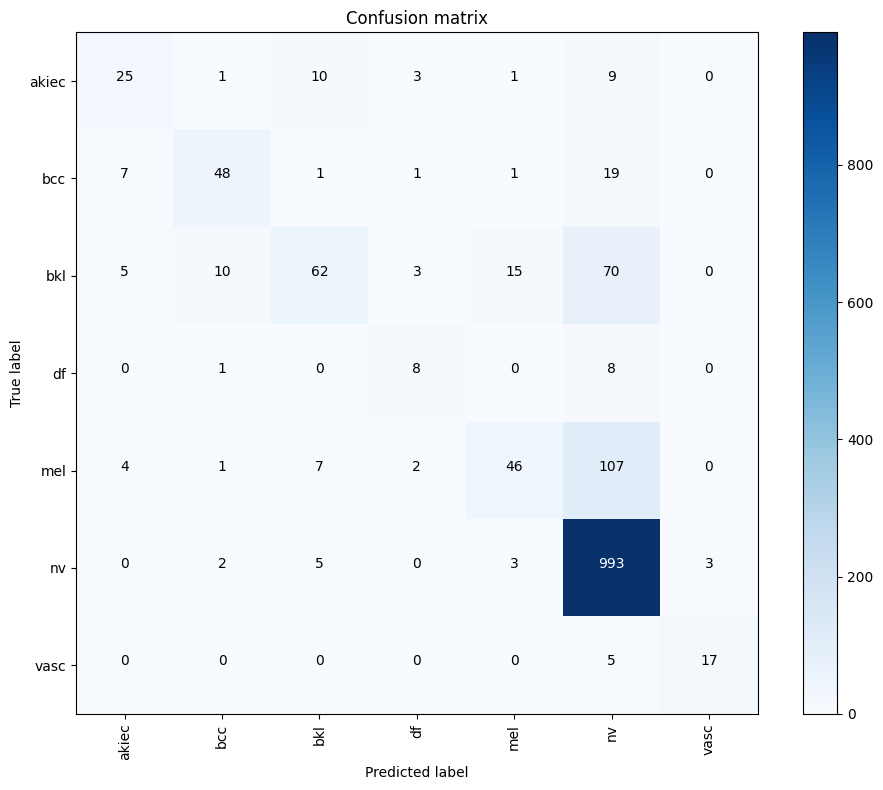

In [2]:
# ================================================================
# Evaluation - Safe Version
# ================================================================
def get_preds_safe(generator):
    """Collect predictions from generator safely"""
    preds, labels = [], []
    n_batches = len(generator)
    
    for i in range(n_batches):
        try:
            X, y = generator[i]
            if isinstance(X, tuple):
                p = model.predict(X, verbose=0)
            else:
                p = model.predict(X, verbose=0)
            preds.append(p)
            labels.append(y)
        except Exception as e:
            print(f" Error in batch {i}: {e}")
            continue
    
    if not preds:
        return np.array([]), np.array([])
    
    return np.vstack(preds), np.vstack(labels)

preds, true = get_preds_safe(test_gen)
pred_labels = np.argmax(preds, axis=1)
true_labels = np.argmax(true, axis=1)

acc = accuracy_score(true_labels, pred_labels)
print(f"Test Accuracy: {acc*100:.2f}%")
print("Classification Report:\n", classification_report(true_labels, pred_labels, target_names=le.classes_, digits=4))

cm = confusion_matrix(true_labels, pred_labels)
plt.figure(figsize=(10,8))
plt.imshow(cm, cmap=plt.cm.Blues)
plt.title("Confusion matrix")
plt.colorbar()
plt.xticks(np.arange(len(le.classes_)), le.classes_, rotation=90)
plt.yticks(np.arange(len(le.classes_)), le.classes_)
thresh = cm.max() / 2
for i,j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
    plt.text(j,i,cm[i,j], ha="center", color="white" if cm[i,j]>thresh else "black")
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.tight_layout()
plt.show()

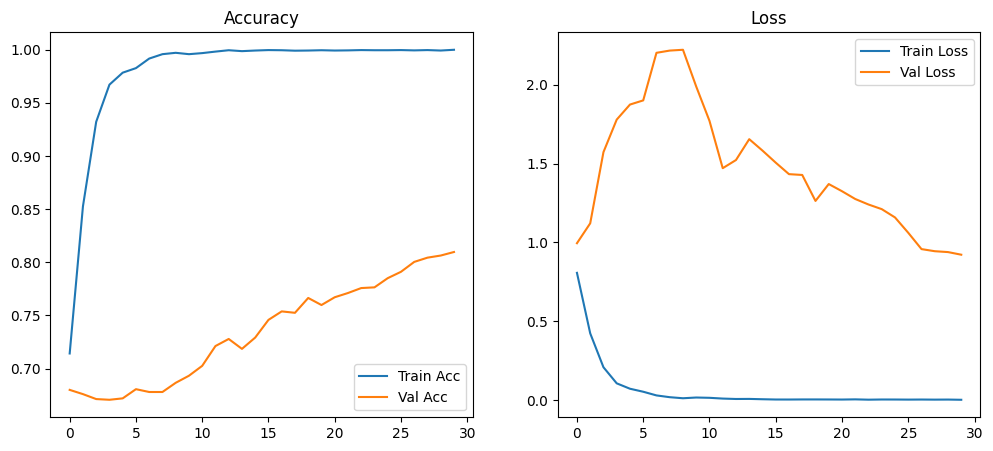

In [3]:
# ================================================================
# Training curves
# ================================================================
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.title("Accuracy")
plt.legend()
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title("Loss")
plt.legend()
plt.show()

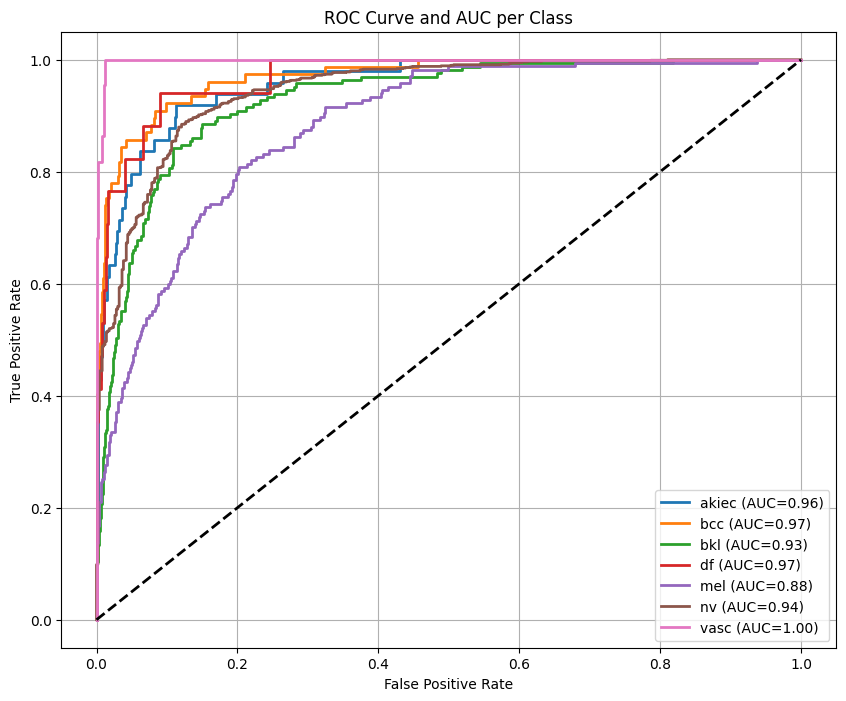

AUC for akiec: 0.9579
AUC for bcc: 0.9697
AUC for bkl: 0.9294
AUC for df: 0.9696
AUC for mel: 0.8825
AUC for nv: 0.9449
AUC for vasc: 0.9978
weighted-average AUC: 0.9714


In [4]:
# ================================================================
# ROC Curves - Safe Version
# ================================================================
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

def collect_predictions_for_roc(generator, model, num_batches=None):
    """Collect predictions from generator safely for ROC"""
    y_true_list = []
    y_pred_list = []
    
    n_batches = len(generator)
    if num_batches is not None:
        n_batches = min(n_batches, n_batches)
    
    if n_batches == 0:
        print(" Warning: Generator has no batches!")
        return np.array([]), np.array([])
    
    for i in range(n_batches):
        try:
            batch_x, batch_y = generator[i]
            
            if isinstance(batch_x, tuple):
                batch_pred = model.predict(batch_x, verbose=0)
            else:
                batch_pred = model.predict(batch_x, verbose=0)
            
            y_true_list.append(batch_y)
            y_pred_list.append(batch_pred)
            
        except Exception as e:
            print(f" Error in batch {i}: {e}")
            continue
    
    if not y_true_list:
        print(" No predictions collected!")
        return np.array([]), np.array([])
    
    return np.concatenate(y_true_list, axis=0), np.concatenate(y_pred_list, axis=0)

y_true, y_pred = collect_predictions_for_roc(test_gen, model)

if y_true.size == 0 or y_pred.size == 0:
    print(" Failed to collect predictions, skipping ROC Curves")
else:
    if y_true.ndim == 2:
        y_true_indices = np.argmax(y_true, axis=1)
    else:
        y_true_indices = y_true

    n_classes = y_pred.shape[1]
    class_names = le.classes_

    y_true_bin = label_binarize(y_true_indices, classes=range(n_classes))

    fpr, tpr, roc_auc = {}, {}, {}
    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_pred[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])

    fpr["weighted"], tpr["weighted"], _ = roc_curve(y_true_bin.ravel(), y_pred.ravel())
    roc_auc["weighted"] = auc(fpr["weighted"], tpr["weighted"])

    plt.figure(figsize=(10, 8))
    for i in range(n_classes):
        plt.plot(fpr[i], tpr[i], lw=2, label=f"{class_names[i]} (AUC={roc_auc[i]:.2f})")

    plt.plot([0, 1], [0, 1], 'k--', lw=2)
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title("ROC Curve and AUC per Class")
    plt.legend(loc="lower right")
    plt.grid(True)
    plt.show()

    for i in range(n_classes):
        print(f"AUC for {class_names[i]}: {roc_auc[i]:.4f}")
    print(f"weighted-average AUC: {roc_auc['weighted']:.4f}")

In [5]:
# ================================================================
# Complete Metrics
# ================================================================
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)

precision = precision_score(true_labels, pred_labels, average="weighted")
sensitivity = recall_score(true_labels, pred_labels, average="weighted")
f1 = f1_score(true_labels, pred_labels, average="weighted")

cm = confusion_matrix(true_labels, pred_labels)
TN = []
FP = []
for i in range(len(cm)):
    tn = np.sum(np.delete(np.delete(cm, i, axis=0), i, axis=1))
    fp = np.sum(cm[:, i]) - cm[i, i]
    TN.append(tn)
    FP.append(fp)
specificity = np.mean(np.array(TN) / (np.array(TN) + np.array(FP)))

auc_score = roc_auc_score(true_labels, preds, multi_class="ovr", average="weighted")

print("="*50)
print(" COMPLETE METRICS SUMMARY")
print("="*50)
print(f" Accuracy    : {acc*100:.2f}%")
print(f" Specificity : {specificity*100:.2f}%")
print(f" Precision   : {precision*100:.2f}%")
print(f" Sensitivity : {sensitivity*100:.2f}%")
print(f" F1 Score    : {f1*100:.2f}%")
print("="*50)

 COMPLETE METRICS SUMMARY
 Accuracy    : 79.77%
 Specificity : 92.85%
 Precision   : 78.30%
 Sensitivity : 79.77%
 F1 Score    : 76.83%
